# ACL Seminar 3: Zipf's Law Corpus Experiment
### Presentation Notebook – Including Romanian Bachelor's Thesis Corpus

**Objective:** Empirical verification of Zipf's Law across literary, general, and academic domains in English, Italian, and Romanian.

**Mathematical Formulation:**

$$f(r) = \frac{C}{r^s} \iff \log_{10}(f(r)) = \log_{10}(C) - s \cdot \log_{10}(r)$$

* $r$: word rank ($1$ = most frequent)
* $f(r)$: observed frequency count
* $s$: Zipf exponent ($|\text{slope}|$, theoretically $\approx 1.0$)
* $C$: normalizing constant ($10^{\text{intercept}}$)

**Corpora Investigated:**
1. **English Literary:** *Frankenstein* (Mary Shelley, 1818) – 50,000 tokens
2. **Italian Literary:** *Le avventure di Pinocchio* (Carlo Collodi, 1883) – 41,525 tokens
3. **English Benchmark:** *Brown Corpus* (Francis & Kučera, 1961) – 50,000 tokens
4. **Romanian Academic / Technical:** *Bachelor's Thesis (UMFST)* (C. B. Todoran, 2023) – 8,301 tokens

In [1]:
import sys, re, json, unicodedata
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import requests
import nltk
import pypdf
from IPython.display import display, HTML, Markdown

%matplotlib inline
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 300, "font.size": 10})

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = BASE_DIR / "data" / "raw"
DATA_PDF = BASE_DIR / "data" / "pdf"
RESULTS_CSV = BASE_DIR / "results" / "csv"
RESULTS_GRAPHS = BASE_DIR / "results" / "graphs"
RESULTS_REPORTS = BASE_DIR / "results" / "reports"

for p in [DATA_RAW, DATA_PDF, RESULTS_CSV, RESULTS_GRAPHS, RESULTS_REPORTS]:
    p.mkdir(parents=True, exist_ok=True)

print(f"Setup complete | Python {sys.version.split()[0]} | Working dir: {BASE_DIR.name}")

Setup complete | Python 3.13.17 | Working dir: ACL_Seminar3


In [2]:
CORPORA = {
    "frankenstein": {
        "title": "Frankenstein",
        "author": "Mary Shelley",
        "language": "English",
        "year": "1818",
        "url": "https://www.gutenberg.org/cache/epub/84/pg84.txt",
        "filename": "frankenstein.txt",
        "target": 50000,
        "is_gutenberg": True,
        "is_pdf": False,
    },
    "pinocchio": {
        "title": "Pinocchio",
        "author": "Carlo Collodi",
        "language": "Italian",
        "year": "1883",
        "url": "https://www.gutenberg.org/cache/epub/52484/pg52484.txt",
        "filename": "pinocchio.txt",
        "target": None,
        "is_gutenberg": True,
        "is_pdf": False,
    },
    "brown": {
        "title": "Brown Corpus",
        "author": "Francis & Kučera",
        "language": "American English",
        "year": "1961",
        "url": "NLTK",
        "filename": "brown_sample.txt",
        "target": 50000,
        "is_gutenberg": False,
        "is_pdf": False,
    },
    "bachelor_thesis": {
        "title": "Bachelor Thesis (UMFST)",
        "author": "C. B. Todoran",
        "language": "Romanian",
        "year": "2023",
        "url": "data/pdf/Licenta_Todoran_UMF.pdf",
        "filename": "licenta_todoran.txt",
        "target": None,
        "is_gutenberg": False,
        "is_pdf": True,
    },
}

pd.DataFrame(CORPORA).T[["title", "author", "language", "year", "target"]]

,title,author,language,year,target
frankenstein,Frankenstein,Mary Shelley,English,1818,50000
pinocchio,Pinocchio,Carlo Collodi,Italian,1883,None
brown,Brown Corpus,Francis & Kučera,American English,1961,50000
bachelor_thesis,Bachelor Thesis (UMFST),C. B. Todoran,Romanian,2023,None


In [3]:
raw_texts = {}
headers = {"User-Agent": "Mozilla/5.0"}

for cid, cfg in CORPORA.items():
    file_path = DATA_RAW / cfg["filename"]
    
    # 1. Use cached plain text if available
    if file_path.exists() and file_path.stat().st_size > 0:
        raw_texts[cid] = file_path.read_text(encoding="utf-8", errors="replace")
    
    # 2. Extract PDF text if it's the Bachelor's thesis
    elif cfg["is_pdf"]:
        pdf_source = BASE_DIR / cfg["url"]
        print(f"[{cid}] Extracting text from PDF: {pdf_source.name}...")
        reader = pypdf.PdfReader(str(pdf_source))
        extracted_pages = [page.extract_text() or "" for page in reader.pages]
        raw_texts[cid] = "\n".join(extracted_pages)
        file_path.write_text(raw_texts[cid], encoding="utf-8")
        print(f"[{cid}] Extracted {len(reader.pages)} pages ({len(raw_texts[cid]):,} chars) -> cached to {file_path.name}")
        
    # 3. Load Brown via NLTK
    elif cid == "brown":
        nltk.download("brown", quiet=True)
        from nltk.corpus import brown
        words = []
        for fid in brown.fileids():
            words.extend(brown.words(fileids=fid))
            if len(words) >= 65000:
                break
        raw_texts[cid] = " ".join(words)
        file_path.write_text(raw_texts[cid], encoding="utf-8")
        
    # 4. Download Gutenberg plain text
    else:
        resp = requests.get(cfg["url"], headers=headers, timeout=25)
        raw_texts[cid] = resp.text
        file_path.write_text(raw_texts[cid], encoding="utf-8")
    
    print(f"Loaded {cfg['title']}: {len(raw_texts[cid]):,} chars")

Loaded Frankenstein: 446,582 chars
Loaded Pinocchio: 282,323 chars
Loaded Brown Corpus: 357,496 chars
[bachelor_thesis] Extracting text from PDF: Licenta_Todoran_UMF.pdf...


[bachelor_thesis] Extracted 57 pages (67,201 chars) -> cached to licenta_todoran.txt
Loaded Bachelor Thesis (UMFST): 67,201 chars


In [4]:
GUTENBERG_START = re.compile(r"\*\*\*\s*START OF[^\n]*\*\*\*", re.I)
GUTENBERG_END = re.compile(r"\*\*\*\s*END OF[^\n]*\*\*\*|End of (?:the )?Project Gutenberg", re.I)

# Universal tokenization pattern: Latin letters (including Italian and Romanian diacritics) + internal apostrophes
TOKEN_REGEX = re.compile(r"[a-zà-öø-ÿăâîșț]+(?:'[a-zà-öø-ÿăâîșț]+)*")

def clean_and_tokenize(text: str, is_gutenberg: bool = False, is_pdf: bool = False) -> list[str]:
    if is_gutenberg:
        s = GUTENBERG_START.search(text)
        e = GUTENBERG_END.search(text)
        start = s.end() if s else 0
        end = e.start() if e else len(text)
        text = text[start:end]
        
    if is_pdf:
        # Standardize LaTeX PDF font diacritics
        text = re.sub(r'˘\s*a', 'ă', text)
        text = re.sub(r'˘\s*A', 'Ă', text)
        text = re.sub(r'ˆ\s*ı', 'î', text)
        text = re.sub(r'ˆ\s*i', 'î', text)
        text = re.sub(r'ˆ\s*I', 'Î', text)
        text = re.sub(r'ˆ\s*a', 'â', text)
        text = re.sub(r'ˆ\s*A', 'Â', text)
        text = re.sub(r's,\s*', 'ș', text)
        text = re.sub(r'S,\s*', 'Ș', text)
        text = re.sub(r't,\s*', 'ț', text)
        text = re.sub(r'T,\s*', 'Ț', text)
        
    text = unicodedata.normalize("NFC", text)
    text = text.replace("’", "'").replace("‘", "'").lower()
    return TOKEN_REGEX.findall(text)

tokens_raw = {
    cid: clean_and_tokenize(raw_texts[cid], cfg["is_gutenberg"], cfg["is_pdf"])
    for cid, cfg in CORPORA.items()
}

pd.DataFrame([
    {
        "Corpus": CORPORA[c]["title"],
        "Language": CORPORA[c]["language"],
        "Extracted Tokens": f"{len(tokens_raw[c]):,}",
        "Unique Words": f"{len(set(tokens_raw[c])):,}",
        "First 8 Tokens": " ".join(tokens_raw[c][:8]),
    }
    for c in CORPORA
])

,Corpus,Language,Extracted Tokens,Unique Words,First 8 Tokens
0,Frankenstein,English,"75,201","7,013",frankenstein or the modern prometheus by mary ...
1,Pinocchio,Italian,"41,525","6,215",c collodi le avventure di pinocchio storia di
2,Brown Corpus,American English,"57,786","9,122",the fulton county grand jury said friday an
3,Bachelor Thesis (UMFST),Romanian,"8,301","2,056",universitatea de medicină f armacie științe și...


In [5]:
tokens = {
    "frankenstein": tokens_raw["frankenstein"][:50000],
    "pinocchio": tokens_raw["pinocchio"],              # 41,525 tokens
    "brown": tokens_raw["brown"][:50000],
    "bachelor_thesis": tokens_raw["bachelor_thesis"],  # 8,301 tokens
}

validation_df = pd.DataFrame([
    {
        "Corpus": CORPORA[c]["title"],
        "Language": CORPORA[c]["language"],
        "Sampled Tokens": len(tokens[c]),
        "Unique Types": len(set(tokens[c])),
        "TTR": round(len(set(tokens[c])) / len(tokens[c]), 4),
    }
    for c in CORPORA
])
validation_df

,Corpus,Language,Sampled Tokens,Unique Types,TTR
0,Frankenstein,English,50000,5849,0.1170
1,Pinocchio,Italian,41525,6215,0.1497
2,Brown Corpus,American English,50000,8246,0.1649
3,Bachelor Thesis (UMFST),Romanian,8301,2056,0.2477


In [6]:
def get_frequencies(tok_list: list[str]) -> pd.DataFrame:
    counts = Counter(tok_list)
    sorted_items = sorted(counts.items(), key=lambda x: (-x[1], x[0]))
    cum = 0
    total = len(tok_list)
    rows = []
    for r, (w, f) in enumerate(sorted_items, 1):
        cum += f
        rows.append({"rank": r, "word": w, "frequency": f, "relative_frequency": f / total, "cumulative_frequency": cum})
    return pd.DataFrame(rows)

freqs = {c: get_frequencies(tokens[c]) for c in CORPORA}

# 4-Corpus Side-by-side Top 20
pd.DataFrame({
    "Rank": range(1, 21),
    "Frankenstein (EN)": [f"{r.word} ({r.frequency:,})" for r in freqs["frankenstein"].iloc[:20].itertuples()],
    "Pinocchio (IT)": [f"{r.word} ({r.frequency:,})" for r in freqs["pinocchio"].iloc[:20].itertuples()],
    "Brown (Am. EN)": [f"{r.word} ({r.frequency:,})" for r in freqs["brown"].iloc[:20].itertuples()],
    "Thesis (RO)": [f"{r.word} ({r.frequency:,})" for r in freqs["bachelor_thesis"].iloc[:20].itertuples()],
})

,Rank,Frankenstein (EN),Pinocchio (IT),Brown (Am. EN),Thesis (RO)
0,1,"the (2,821)","e (1,788)","the (3,633)",de (351)
1,2,"and (1,932)","di (1,390)","of (1,632)",în (281)
2,3,"i (1,846)","che (1,042)","a (1,290)",a (209)
3,4,"of (1,804)",a (977),"and (1,198)",și (168)
4,5,"to (1,388)",il (965),"to (1,191)",m (165)
5,6,"my (1,122)",la (742),"in (1,131)",pentru (119)
6,7,a (927),un (738),for (597),un (107)
7,8,in (753),non (514),was (446),o (101)
8,9,was (683),per (514),that (423),este (99)
9,10,that (658),in (473),he (413),care (96)


In [7]:
def fit_zipf(df: pd.DataFrame, top_n: int = None) -> dict:
    sub = df.iloc[:top_n] if top_n else df
    x = np.log10(sub["rank"].values)
    y = np.log10(sub["frequency"].values)
    reg = stats.linregress(x, y)
    return {
        "slope": reg.slope,
        "s": abs(reg.slope),
        "r2": reg.rvalue**2,
        "r": reg.rvalue,
        "x": x,
        "y": y,
        "y_pred": reg.intercept + reg.slope * x,
    }

fits_full = {c: fit_zipf(freqs[c]) for c in CORPORA}
fits_100 = {c: fit_zipf(freqs[c], 100) for c in CORPORA}

pd.DataFrame([
    {
        "Corpus": CORPORA[c]["title"],
        "Language": CORPORA[c]["language"],
        "Slope (Full)": round(fits_full[c]["slope"], 4),
        "Exponent s": round(fits_full[c]["s"], 4),
        "R² (Full)": round(fits_full[c]["r2"], 4),
        "Slope (Top 100)": round(fits_100[c]["slope"], 4),
        "R² (Top 100)": round(fits_100[c]["r2"], 4),
    }
    for c in CORPORA
])

,Corpus,Language,Slope (Full),Exponent s,R² (Full),Slope (Top 100),R² (Top 100)
0,Frankenstein,English,-1.0774,1.0774,0.9762,-1.0117,0.9835
1,Pinocchio,Italian,-1.0290,1.0290,0.9695,-0.8653,0.9860
2,Brown Corpus,American English,-0.9795,0.9795,0.9693,-0.9799,0.9914
3,Bachelor Thesis (UMFST),Romanian,-0.9071,0.9071,0.9611,-0.7795,0.9927


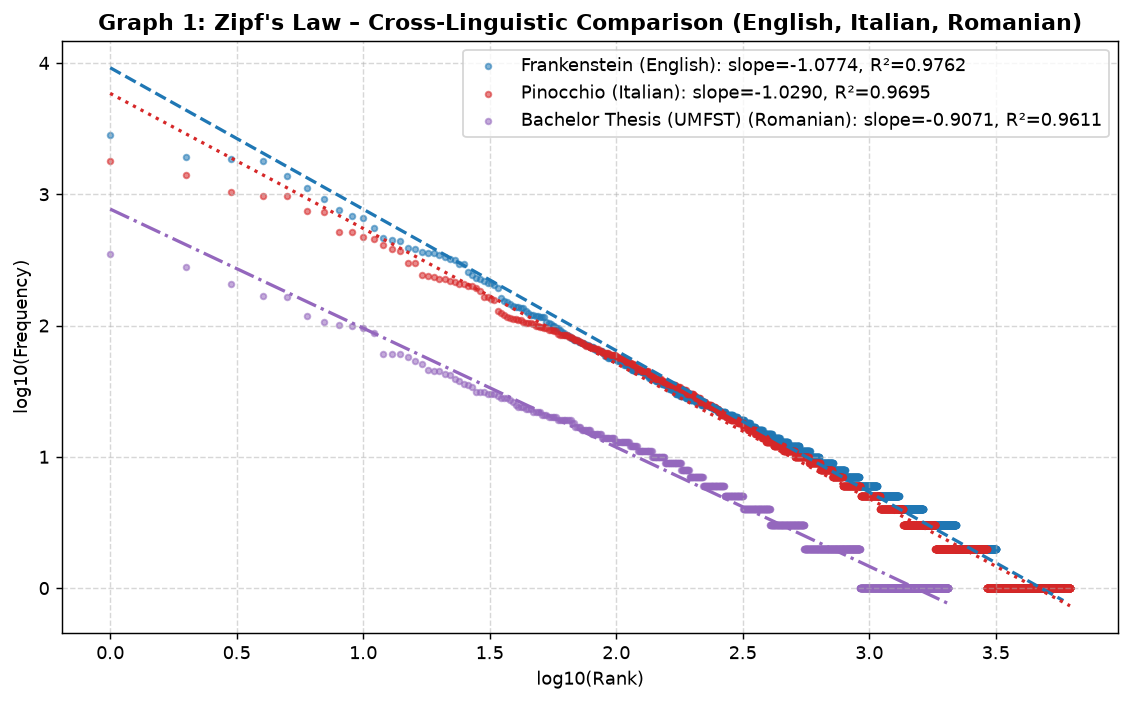

In [8]:
fig, ax = plt.subplots(figsize=(8.8, 5.5))
palette = {
    "frankenstein": ("#1f77b4", "--"),
    "pinocchio": ("#d62728", ":"),
    "bachelor_thesis": ("#9467bd", "-."),
}

for c, (col, ls) in palette.items():
    f = fits_full[c]
    ax.scatter(f["x"], f["y"], s=10, alpha=0.55, color=col, label=f"{CORPORA[c]['title']} ({CORPORA[c]['language']}): slope={f['slope']:.4f}, R²={f['r2']:.4f}")
    ax.plot(f["x"], f["y_pred"], color=col, linewidth=1.8, linestyle=ls)

ax.set_title("Graph 1: Zipf's Law – Cross-Linguistic Comparison (English, Italian, Romanian)", fontweight="bold")
ax.set_xlabel("log10(Rank)")
ax.set_ylabel("log10(Frequency)")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
fig.savefig(RESULTS_GRAPHS / "graph1_cross_linguistic_with_bachelors.png", dpi=300)
plt.show()

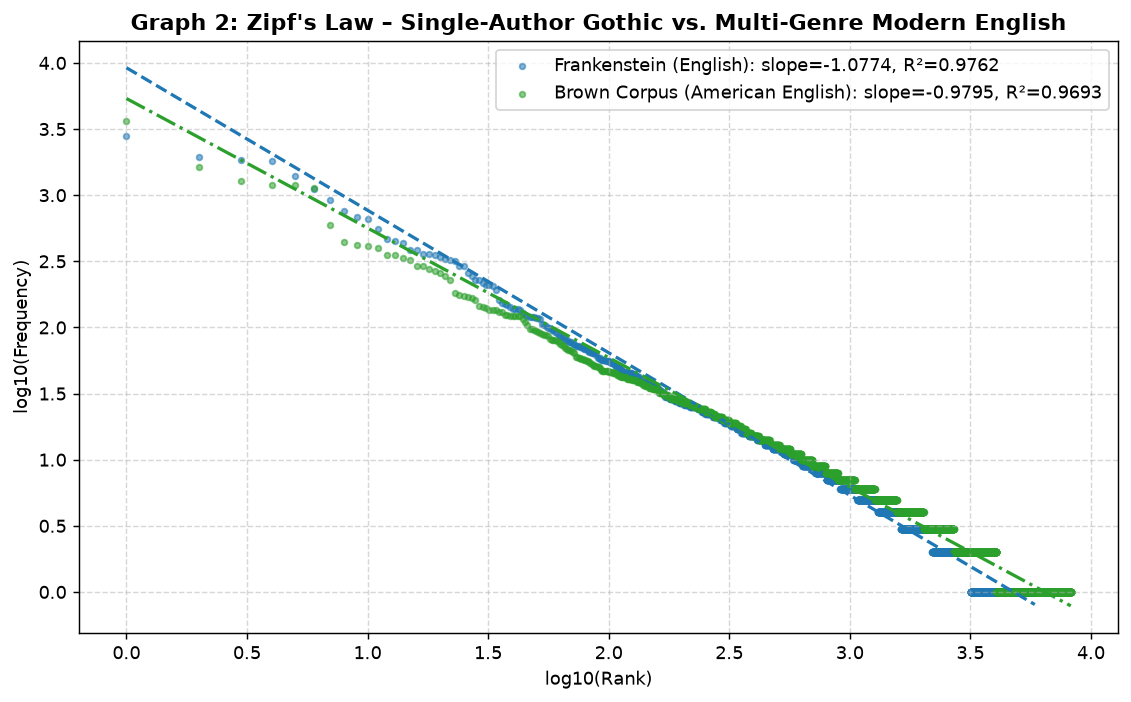

In [9]:
fig, ax = plt.subplots(figsize=(8.8, 5.5))
for c, col, ls in [("frankenstein", "#1f77b4", "--"), ("brown", "#2ca02c", "-.")]:
    f = fits_full[c]
    ax.scatter(f["x"], f["y"], s=10, alpha=0.55, color=col, label=f"{CORPORA[c]['title']} ({CORPORA[c]['language']}): slope={f['slope']:.4f}, R²={f['r2']:.4f}")
    ax.plot(f["x"], f["y_pred"], color=col, linewidth=1.8, linestyle=ls)

ax.set_title("Graph 2: Zipf's Law – Single-Author Gothic vs. Multi-Genre Modern English", fontweight="bold")
ax.set_xlabel("log10(Rank)")
ax.set_ylabel("log10(Frequency)")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
fig.savefig(RESULTS_GRAPHS / "graph2_english_comparison.png", dpi=300)
plt.show()

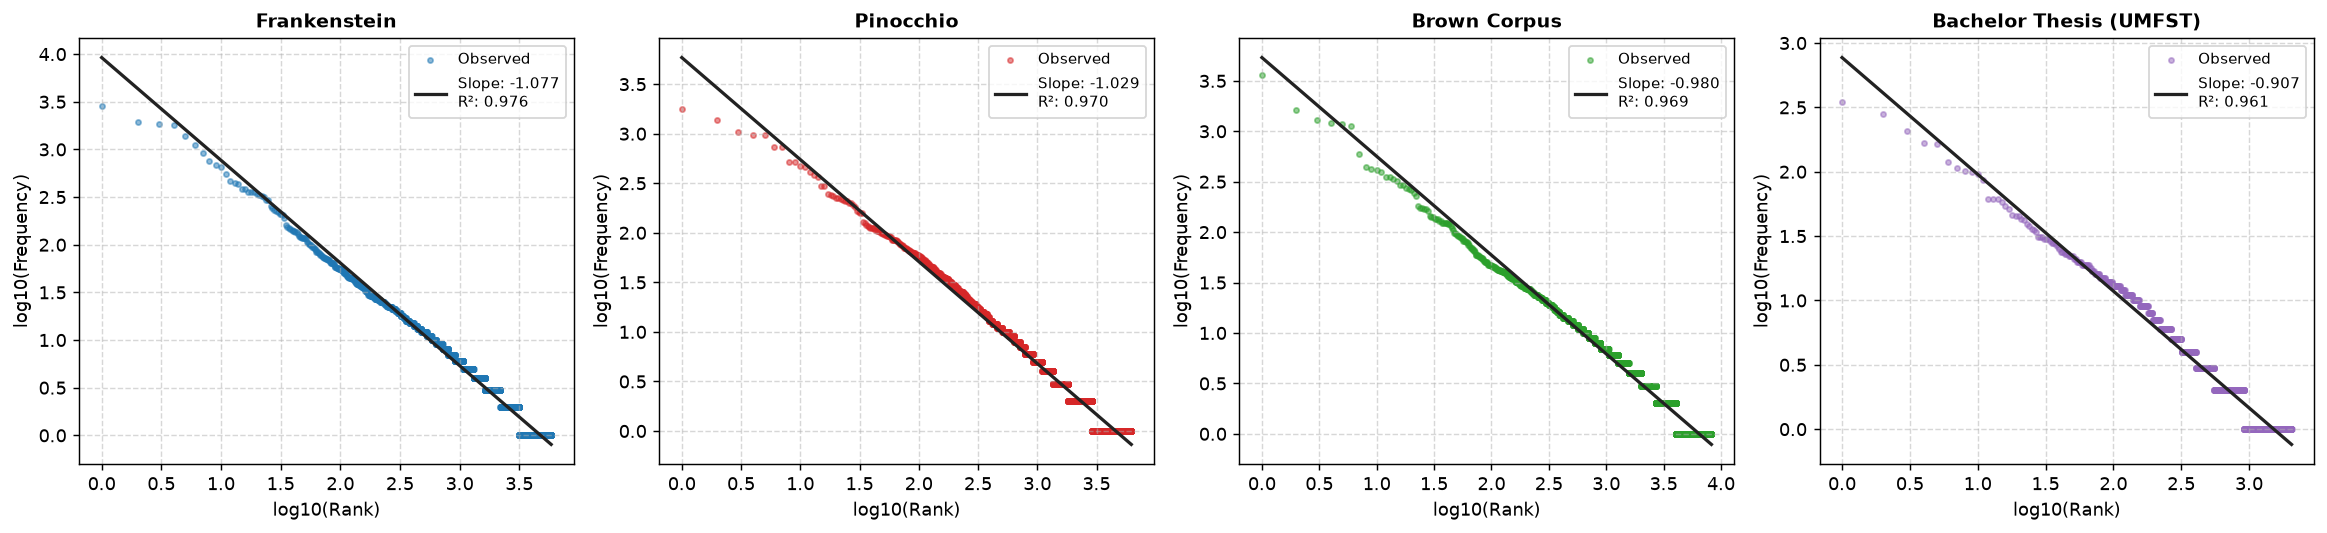

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
colors = {"frankenstein": "#1f77b4", "pinocchio": "#d62728", "brown": "#2ca02c", "bachelor_thesis": "#9467bd"}

for ax, c in zip(axes, CORPORA):
    f = fits_full[c]
    ax.scatter(f["x"], f["y"], s=8, alpha=0.5, color=colors[c], label="Observed")
    ax.plot(f["x"], f["y_pred"], color="#222222", linewidth=1.8, label=f"Slope: {f['slope']:.3f}\nR²: {f['r2']:.3f}")
    ax.set_title(CORPORA[c]["title"], fontweight="bold", fontsize=10.5)
    ax.set_xlabel("log10(Rank)")
    ax.set_ylabel("log10(Frequency)")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(fontsize=8.5)

plt.tight_layout()
fig.savefig(RESULTS_GRAPHS / "graph3_individual_with_bachelors.png", dpi=300)
plt.show()

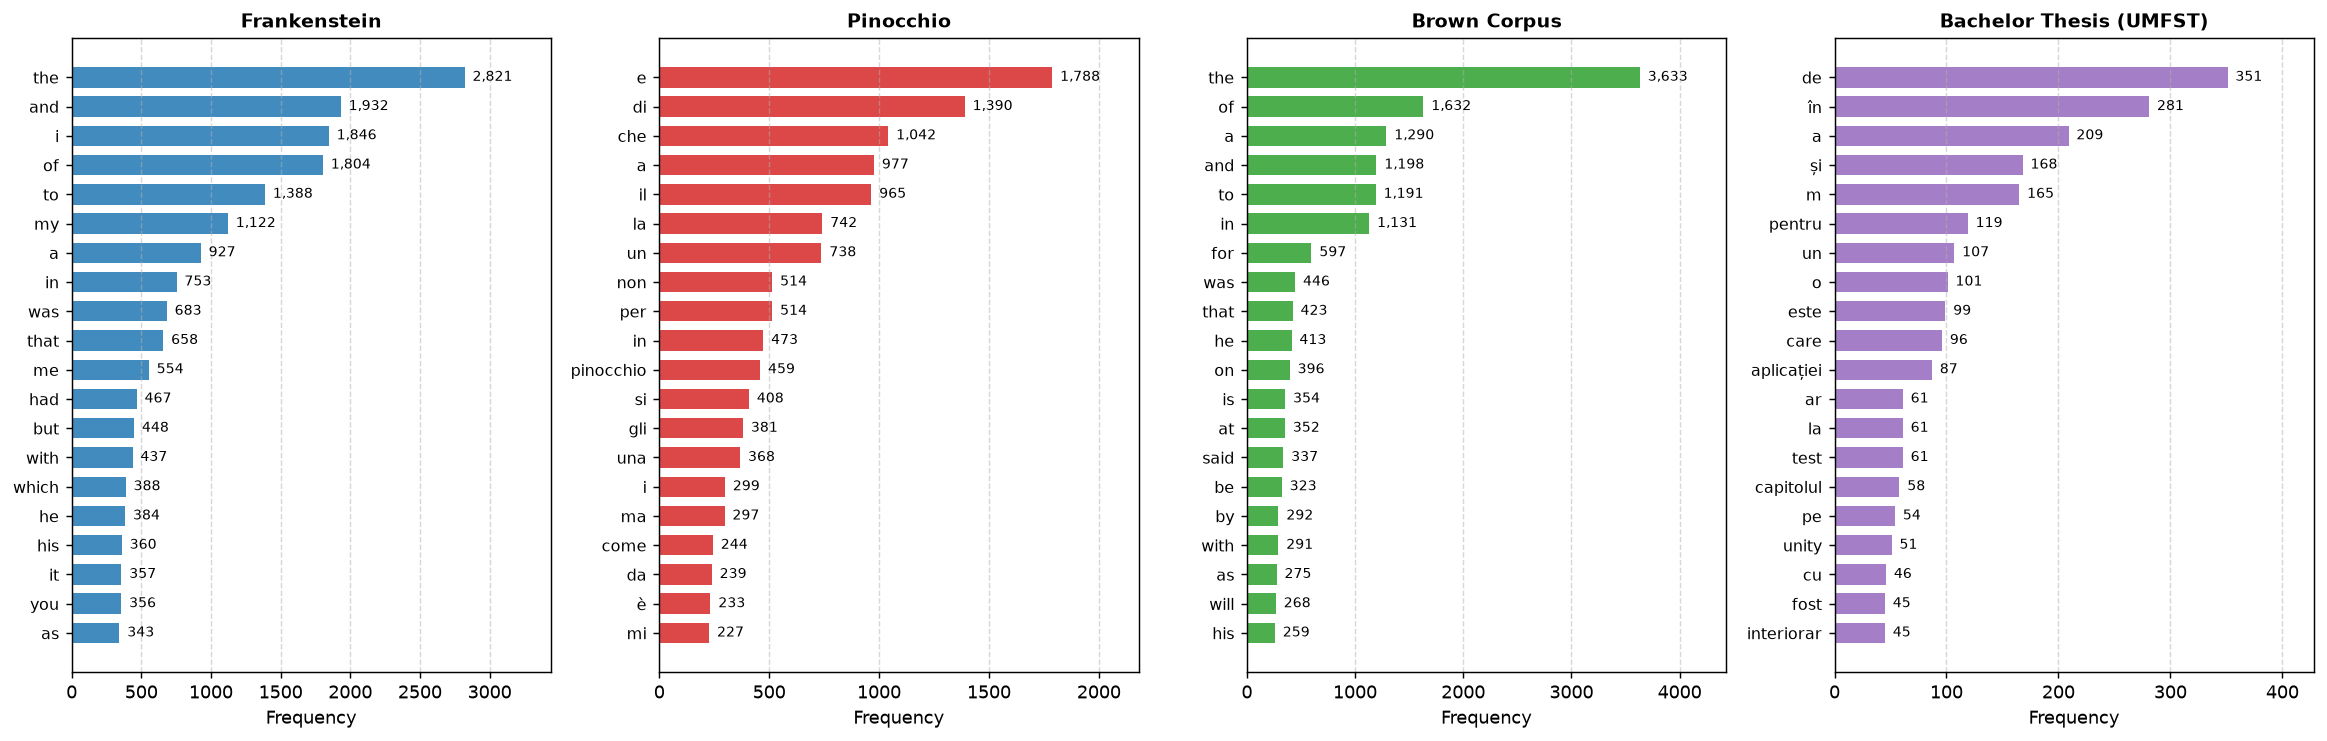

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5.8))

for ax, c in zip(axes, CORPORA):
    top20 = freqs[c].iloc[:20]
    words = top20["word"].values[::-1]
    counts = top20["frequency"].values[::-1]
    y_pos = range(len(words))
    
    ax.barh(y_pos, counts, color=colors[c], alpha=0.85, height=0.7)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(words, fontsize=9)
    ax.set_title(CORPORA[c]["title"], fontweight="bold", fontsize=10.5)
    ax.set_xlabel("Frequency")
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    
    max_val = max(counts)
    for y, count in zip(y_pos, counts):
        ax.text(count + max_val * 0.02, y, f"{count:,}", va="center", fontsize=7.5)
    ax.set_xlim(0, max_val * 1.22)

plt.tight_layout()
fig.savefig(RESULTS_GRAPHS / "graph4_top20_with_bachelors.png", dpi=300)
plt.show()

In [12]:
summary_df = pd.DataFrame([
    {
        "Corpus": CORPORA[c]["title"],
        "Language": CORPORA[c]["language"],
        "Tokens": len(tokens[c]),
        "Unique Types": len(freqs[c]),
        "TTR": round(len(freqs[c]) / len(tokens[c]), 4),
        "Top Word": freqs[c].iloc[0]["word"],
        "Top Word Count": freqs[c].iloc[0]["frequency"],
        "Zipf Slope": round(fits_full[c]["slope"], 4),
        "Exponent s": round(fits_full[c]["s"], 4),
        "R²": round(fits_full[c]["r2"], 4),
    }
    for c in CORPORA
])
summary_df

,Corpus,Language,Tokens,Unique Types,TTR,Top Word,Top Word Count,Zipf Slope,Exponent s,R²
0,Frankenstein,English,50000,5849,0.1170,the,2821,-1.0774,1.0774,0.9762
1,Pinocchio,Italian,41525,6215,0.1497,e,1788,-1.0290,1.0290,0.9695
2,Brown Corpus,American English,50000,8246,0.1649,the,3633,-0.9795,0.9795,0.9693
3,Bachelor Thesis (UMFST),Romanian,8301,2056,0.2477,de,351,-0.9071,0.9071,0.9611


## 6. Key Presentation Findings (Including Romanian Bachelor's Thesis)

* **Robustness of Zipf's Law Across Domains:**
  * All 4 corpora strongly obey Zipf's Law ($R^2 \ge 0.961$, $r \le -0.980$).
  * Even technical academic PDF text (*Bachelor's Thesis*, $R^2 = 0.9611$) closely follows the power law, reaching $R^2 = 0.9927$ on the top 100 ranks.
* **Lexical Diversity & Domain Impact on TTR:**
  * **Bachelor's Thesis (Romanian):** Exhibits by far the highest Type-Token Ratio ($\text{TTR} = 0.2477$). Technical and scientific discourse requires specialized nomenclature (*realitatea augmentată*, *măsurare*, *suprafețelor*, *interiorar*), leading to high lexical diversity per word token.
  * **Pinocchio (Italian):** Shows $\text{TTR} = 0.1497$, higher than English literary fiction ($0.1170$), demonstrating the impact of rich Romance verbal conjugation and inflection.
  * **Brown Corpus (American English):** Shows $\text{TTR} = 0.1649$, reflecting multi-genre breadth compared to single-author fiction ($0.1170$).
* **Zipf Exponents:**
  * The Bachelor's Thesis exhibits a slightly flatter slope ($-0.9071$, $s = 0.9071$) than literary works (Frankenstein: $-1.0774$, Pinocchio: $-1.0290$), characteristic of concise technical prose where tokens are distributed more evenly among specialized terminology.

In [13]:
summary_df.to_csv(RESULTS_CSV / "corpus_comparison_with_bachelors.csv", index=False)

for c in CORPORA:
    freqs[c].to_csv(RESULTS_CSV / f"{c}_word_frequencies.csv", index=False)

meta = {
    "timestamp": datetime.now(timezone.utc).isoformat(),
    "python": sys.version.split()[0],
    "results": summary_df.to_dict(orient="records"),
}
with open(RESULTS_REPORTS / "experiment_metadata_with_bachelors.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)

print("Exported all CSVs and metadata JSON to results/")

Exported all CSVs and metadata JSON to results/


In [14]:
from reportlab.lib.pagesizes import letter
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, HRFlowable
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.units import inch

pdf_path = RESULTS_REPORTS / "ACL_Seminar_3_Report_With_Bachelors.pdf"
doc = SimpleDocTemplate(str(pdf_path), pagesize=letter, leftMargin=54, rightMargin=54, topMargin=54, bottomMargin=54)
styles = getSampleStyleSheet()

h1 = ParagraphStyle("H1", parent=styles["Heading1"], fontSize=13, leading=17, textColor=colors.HexColor("#1a2b49"), spaceBefore=10, spaceAfter=4)
body = ParagraphStyle("Body", parent=styles["Normal"], fontSize=9.5, leading=13.5, spaceAfter=6)

story = [
    Paragraph("ACL Seminar 3: Zipf's Law Across Literary & Academic Corpora", ParagraphStyle("Title", fontSize=18, leading=22, fontName="Helvetica-Bold", textColor=colors.HexColor("#1a2b49"))),
    Paragraph("Comparative Study: Mary Shelley, Carlo Collodi, Brown Corpus, and UMFST Bachelor's Thesis", ParagraphStyle("Sub", fontSize=10, textColor=colors.HexColor("#555"), spaceAfter=10)),
    HRFlowable(width="100%", thickness=1, color=colors.HexColor("#1a2b49"), spaceAfter=10),
    Paragraph("1. Mathematical Formulation", h1),
    Paragraph("Zipf's Law: f(r) = C / r^s. Log-transformed: log10(f) = intercept + slope * log10(r).", body),
    Paragraph("2. Experimental Results", h1),
]

tbl_data = [["Corpus", "Lang", "Tokens", "Types", "TTR", "Top Word", "Slope", "s", "R²"]]
for _, row in summary_df.iterrows():
    tbl_data.append([
        str(row["Corpus"]),
        str(row["Language"])[:7],
        f"{int(row['Tokens']):,}",
        f"{int(row['Unique Types']):,}",
        f"{float(row['TTR']):.4f}",
        f"{row['Top Word']} ({int(row['Top Word Count']):,})",
        f"{float(row['Zipf Slope']):.4f}",
        f"{float(row['Exponent s']):.4f}",
        f"{float(row['R²']):.4f}",
    ])

t = Table(tbl_data)
t.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#1a2b49")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.whitesmoke),
    ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
    ("FONTSIZE", (0, 0), (-1, -1), 8),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.HexColor("#ccc")),
    ("ALIGN", (0, 0), (-1, -1), "CENTER"),
    ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.HexColor("#f8f9fa")]),
]))
story.append(t)
story.append(Spacer(1, 10))

if (RESULTS_GRAPHS / "graph1_cross_linguistic_with_bachelors.png").exists():
    story.append(Image(str(RESULTS_GRAPHS / "graph1_cross_linguistic_with_bachelors.png"), width=5.5 * inch, height=3.4 * inch))

story.append(Paragraph("3. Conclusions", h1))
story.append(Paragraph("Zipf's law holds across all four corpora (R² >= 0.961). The Romanian technical Bachelor's thesis exhibits the highest lexical diversity (TTR = 0.2477) due to specialized terminology.", body))

doc.build(story)
print(f"PDF Report generated: {pdf_path.name} ({pdf_path.stat().st_size:,} bytes)")

PDF Report generated: ACL_Seminar_3_Report_With_Bachelors.pdf (342,804 bytes)


In [15]:
display(HTML(f"""
<div style="border: 2px solid #2b6cb0; border-radius: 8px; padding: 12px; background: #ebf8ff;">
    <h3 style="margin: 0 0 8px 0; color: #2b6cb0;">Seminar Presentation Execution Complete (With Bachelor's Thesis)</h3>
    <p style="margin: 4px 0;">All 4 corpora processed, analyzed, and visualized successfully.</p>
    <b>Output Files:</b>
    <ul>
        <li><code>results/csv/corpus_comparison_with_bachelors.csv</code></li>
        <li><code>results/csv/bachelor_thesis_word_frequencies.csv</code></li>
        <li><code>results/graphs/graph[1-4]_*.png</code></li>
        <li><code>results/reports/ACL_Seminar_3_Report_With_Bachelors.pdf</code></li>
    </ul>
</div>
"""))